# WaveCatBoost in R

Notebook of the project code: Haar MODWT + one boosting model per wavelet component, inverse reconstruction, and conformal intervals.

This is an EDA-driven R implementation of Borah et al., *A Novel Hybrid Approach for Efficiently Forecasting Air Quality Data* (IEEE Sensors Letters, 2025), plus AR/SARIMA and other boosting models with and without MODWT.

The functions live in `R/`. This notebook **sources those files** and walks through them in order, with plots and the cached bake-off in `results/`. The interactive Shiny report is still `analysis.Rmd`.

| File | Role |
|---|---|
| `R/00_packages.R` | CRAN packages; CatBoost GitHub binary or XGBoost fallback |
| `R/01_constants.R` | sensors, pollutants, horizons, alert thresholds |
| `R/02_data.R` | load `CPCB.csv` / `ID1.csv` |
| `R/03_preprocess.R` | clip, seasonal impute, train-only min-max, chronological split |
| `R/04_modwt.R` | circular Haar MODWT / MRA |
| `R/05_features.R` | lag matrix, PACF cutoff |
| `R/06_models.R` | snaive, SARIMA, trees, Wave\* hybrids |
| `R/07_conformal.R` | weighted conformal PI + WHO/NAAQS alert |
| `R/08_metrics.R` | MASE, MAE, RMSE, MCB ranks |
| `R/09_hparams.R` | time-based grid on CPCB PM2.5 train only |

**Kernel:** R (`IRkernel`). Working directory must be the project root.


## 0. Setup

Load helpers. CatBoost is not on CRAN; if the R package is missing, CatBoost / WaveCatBoost slots fall back to XGBoost (labelled in the fit object).


In [1]:
if (!file.exists("R/load_all.R")) {
  stop("Set the working directory to the project root (the folder that contains R/ and data/).")
}
old_warn <- getOption("warn")
options(warn = -1)
suppressPackageStartupMessages(source("R/load_all.R"))
options(warn = old_warn)

options(repr.plot.width = 10, repr.plot.height = 4.8,
        tibble.width = Inf, tibble.print_max = 50)
theme_set(theme_minimal(base_size = 13))

cat("Project root:", PROJECT_ROOT, "\n")
cat("CatBoost available:", isTRUE(CATBOOST_AVAILABLE), "\n")
cat("Sensors:", paste(SENSORS, collapse = ", "), "\n")
cat("Pollutants:", paste(POLLUTANTS, collapse = ", "), "\n")
print(unlist(HORIZONS))


SyntaxError: invalid syntax (1729234712.py, line 1)

## 1. Data collection

Data are the authors' public hourly files ([WaveCatBoost-Time-Series-Model](https://github.com/jborah2/WaveCatBoost-Time-Series-Model)): `CPCB.csv` and `ID1.csv`.

**Choice: use the released hourly CSVs, not a new CPCB scrape.** That is the only way to stay comparable to the paper. Both files are already hourly (median gap = 1 hour). The paper describes 15-minute raw samples that were then averaged; we do **not** invent 15-minute values.

**Choice: univariate series, one pollutant at a time.** CPCB also records air temperature and relative humidity; we plot them in EDA and leave them out of the models.


In [ ]:
cat("Data loaders — see R/02_data.R (load_raw_datasets, sampling_hours).\n")


Data loaders — see R/02_data.R (load_raw_datasets, sampling_hours).


In [ ]:
series_path <- file.path(PROC_DIR, "series.rds")
if (file.exists(series_path)) {
  packed <- readRDS(series_path)
  raw <- packed$raw
  series <- packed$series
} else {
  raw <- load_raw_datasets()
  series <- prepare_all_series(raw)
}

cpcb <- raw$CPCB
id1 <- raw$ID1
tibble::tibble(
  sensor = c("CPCB", "ID1"),
  start = c(min(cpcb$Datetime), min(id1$Datetime)),
  end = c(max(cpcb$Datetime), max(id1$Datetime)),
  n = c(nrow(cpcb), nrow(id1)),
  median_gap_hours = c(sampling_hours(cpcb$Datetime), sampling_hours(id1$Datetime)),
  extra_columns = c("AT, RH", "AT (Temp), RH")
)


sensor,start,end,n,median_gap_hours,extra_columns
<chr>,<dttm>,<dttm>,<int>,<dbl>,<chr>
CPCB,2022-07-01,2023-07-06,8881,1,"AT, RH"
ID1,2022-07-01,2023-08-01,9505,1,"AT (Temp), RH"


## 2. Exploratory analysis

Later modelling choices are **Decisions** that point back to a plot or test here. Default series: CPCB PM2.5.


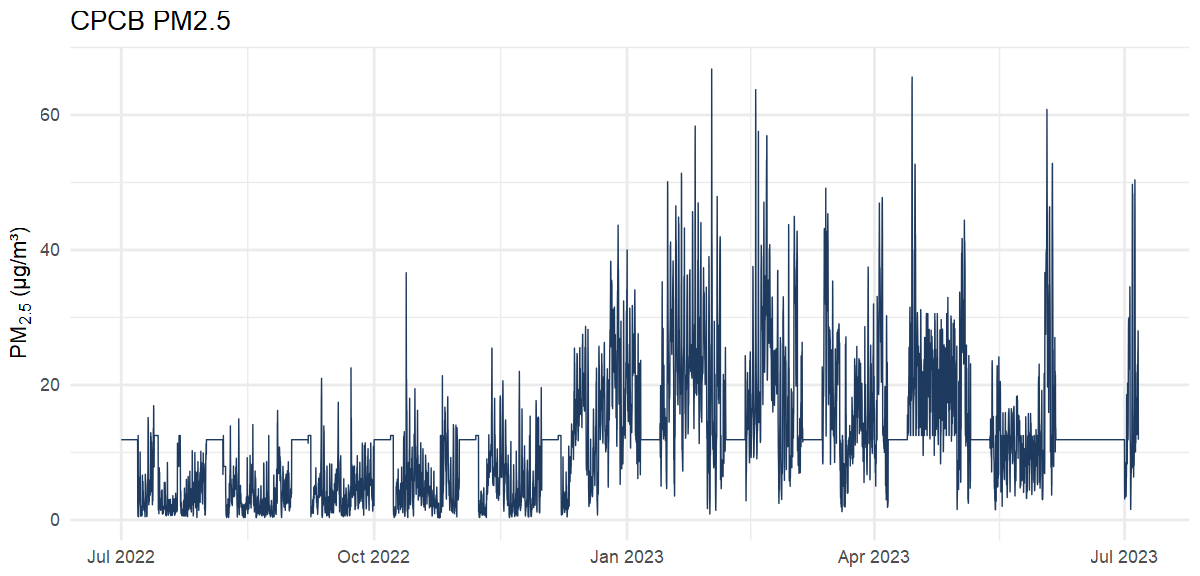

In [ ]:
s <- series[["CPCB_PM2.5"]]
df <- tibble(Datetime = s$times, value = s$y)

ggplot(df, aes(Datetime, value)) +
  geom_line(colour = "#1F3A5F", linewidth = 0.3) +
  labs(title = "CPCB PM2.5", y = expression(PM[2.5]~"(µg/m³)"), x = NULL)


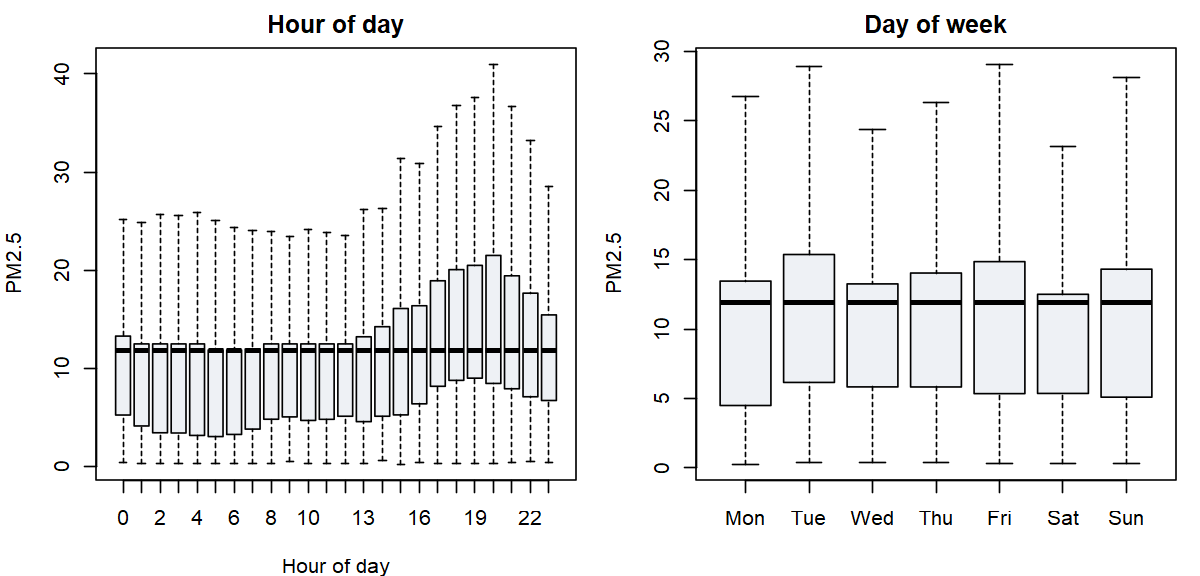

In [ ]:
df_box <- df %>%
  mutate(
    hour = lubridate::hour(Datetime),
    dow = lubridate::wday(Datetime, label = TRUE, week_start = 1)
  )
par(mfrow = c(1, 2), mar = c(4, 4, 2, 1))
boxplot(value ~ hour, data = df_box, outline = FALSE, xlab = "Hour of day",
        ylab = "PM2.5", main = "Hour of day", col = "#EEF1F5")
boxplot(value ~ dow, data = df_box, outline = FALSE, xlab = NULL,
        ylab = "PM2.5", main = "Day of week", col = "#EEF1F5")


**Decision.** Seasonal period $S = 24$ for snaive, SARIMA, and the MASE denominator. Weekly effects exist but are weaker than the daily cycle on these Meghalaya series, so we do not force $S = 168$ in SARIMA.


### 2.1 Missingness

The GitHub CPCB file is already filled: long runs of identical values at the start of July 2022 are almost certainly **pre-imputed**. ID1 is closer to a real low-cost record.


In [ ]:
missing_tbl <- dplyr::bind_rows(lapply(series, function(z) {
  r <- rle(round(z$y, 6))
  tibble(
    sensor = z$sensor, pollutant = z$pollutant,
    n = length(z$y),
    n_missing_in_file = z$n_missing,
    n_clipped_impossible = z$n_impossible,
    n_flat_runs_ge6h = sum(r$lengths >= 6)
  )
}))
missing_tbl


sensor,pollutant,n,n_missing_in_file,n_clipped_impossible,n_flat_runs_ge6h
<chr>,<chr>,<int>,<int>,<int>,<int>
CPCB,NO2,8881,0,0,22
CPCB,O3,8881,0,0,22
CPCB,CO,8881,0,0,22
CPCB,SO2,8881,0,0,22
CPCB,PM2.5,8881,0,0,23
CPCB,PM10,8881,0,0,22
ID1,NO2,9505,0,0,15
ID1,O3,9505,0,0,15
ID1,CO,9505,0,0,51


**Decision.** If a file has no `NA`s we do not re-impute. Remaining `NA`s are filled with seasonal interpolation (`imputeTS::na_seadec`) because EDA shows a 24-hour cycle. Negative concentrations are treated as sensor faults. Genuine pollution spikes are **not** winsorised.


### 2.2 Stationarity, ACF, PACF


In [ ]:
y <- s$y
adf <- tryCatch(tseries::adf.test(y, alternative = "stationary"), error = function(e) NULL)
kpss <- tryCatch(urca::ur.kpss(y, type = "mu"), error = function(e) NULL)
tibble(
  test = c("ADF (H0: unit root)", "KPSS statistic (H0: level stationary)"),
  statistic = c(if (is.null(adf)) NA else unname(adf$statistic),
                if (is.null(kpss)) NA else kpss@teststat),
  p_or_cv = c(if (is.null(adf)) NA else adf$p.value,
              if (is.null(kpss)) NA else kpss@cval[2])
)


Warning message in tseries::adf.test(y, alternative = "stationary"):
"p-value smaller than printed p-value"


test,statistic,p_or_cv
<chr>,<dbl>,<dbl>
ADF (H0: unit root),-7.020178,0.010
KPSS statistic (H0: level stationary),21.506938,0.463


PACF cutoff (95% band, max lag 72): p = 70 hours


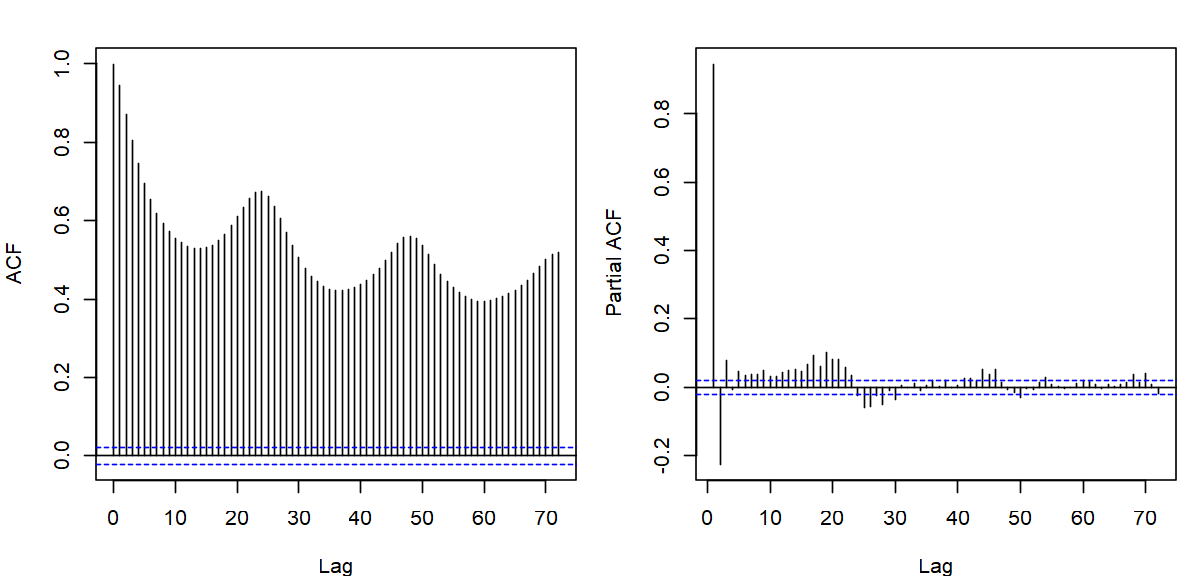

In [ ]:
par(mfrow = c(1, 2), mar = c(4, 4, 2, 1))
acf(y, lag.max = 72, main = "ACF CPCB PM2.5", na.action = na.pass)
pacf(y, lag.max = 72, main = "PACF CPCB PM2.5", na.action = na.pass)
cat("PACF cutoff (95% band, max lag 72): p =", pacf_cutoff(y, max_lag = 72), "hours\n")


**Decision.** These series are not covariance-stationary (shifting mean, daily cycle, spikes). That is why a plain AR on the raw series is a weak baseline, why SARIMA is allowed a seasonal difference, and why MODWT (local in time **and** scale) is the paper's feature step rather than a global Fourier filter.

**Decision.** Tree models use lag window $p = 24$ as the default (one full daily cycle). AR uses the same $p$. We do **not** pick $p$ on the test window.


### 2.3 STL and wavelet energy


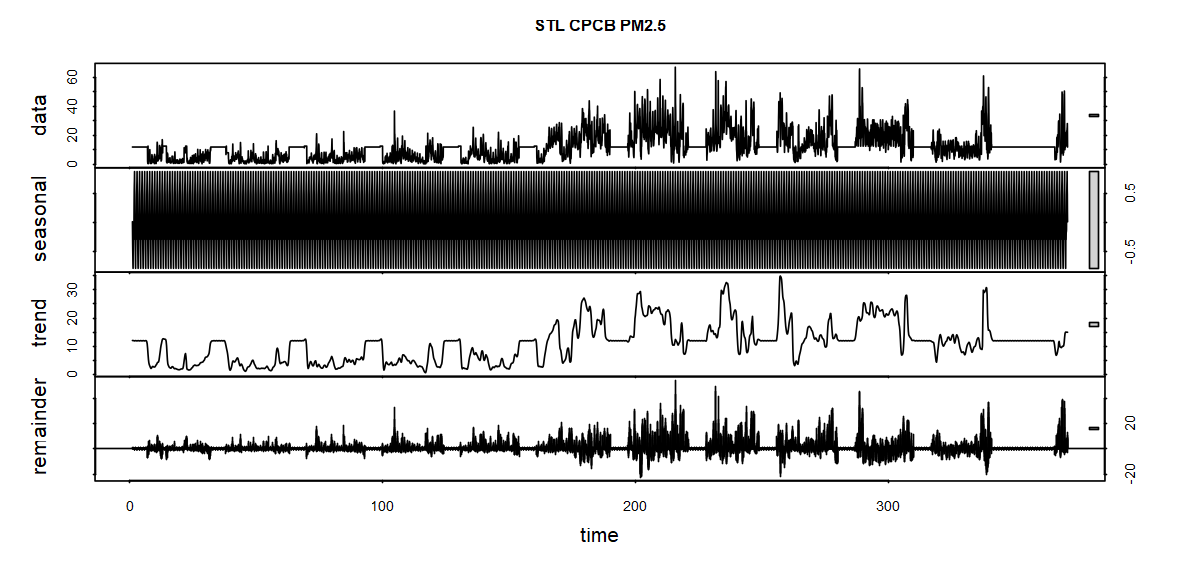

In [ ]:
plot(stl(ts(y, frequency = 24), s.window = "periodic", robust = TRUE),
     main = "STL CPCB PM2.5")


# A tibble: 10 × 3
   component   energy   share
   <chr>        <dbl>   <dbl>
 1 D1           7601. 0.00447
 2 D2          10990. 0.00646
 3 D3          20282. 0.0119 
 4 D4          32055. 0.0189 
 5 D5          14233. 0.00837
 6 D6          15955. 0.00938
 7 D7          17367. 0.0102 
 8 D8          20556. 0.0121 
 9 D9          18995. 0.0112 
10 S9        1542359. 0.907  


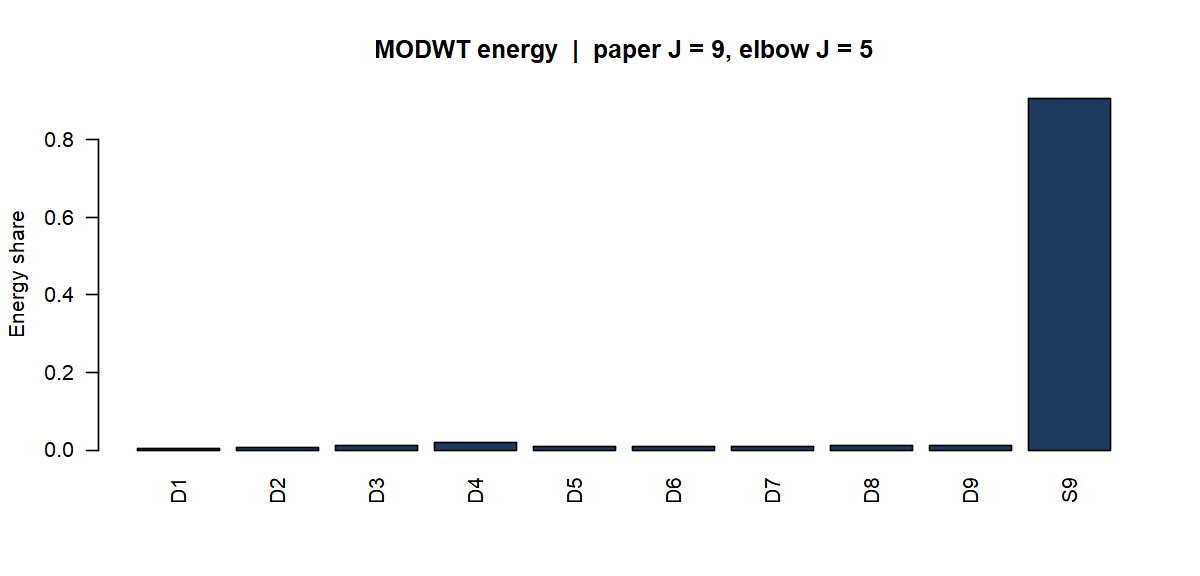

In [ ]:
pick <- choose_J(y)
barplot(pick$energy$share, names.arg = pick$energy$component, las = 2,
        col = "#1F3A5F", ylab = "Energy share",
        main = sprintf("MODWT energy  |  paper J = %s, elbow J = %s",
                       pick$J_paper, pick$J_elbow))
print(pick$energy)


**Decision.** Use Haar, as in Algorithm 1 of the paper. Use $J$ from the energy elbow (typically 4–5 on these hourly series) rather than blindly $K = \ln N \approx 9$: extra levels add one CatBoost model each and mostly fit residual noise. Modelling then **caps $J$ at 5** (scale $2^5 = 32$ hours, one daily cycle).


## 3. Preprocessing

Paper order: missing values → hourly averages → min-max to $[0,1]$.

| Step | What we do | Why |
|---|---|---|
| Hourly average | Skip | Files are already hourly |
| Impossible values | Negatives and absurd caps → NA | Sensor faults, not spikes |
| Imputation | Seasonal interpolation if any NA remain | Preserves the 24 h cycle |
| Min-max | **Train only**, trees and Wave\* trees | Paper; invert after forecast |
| AR / SARIMA / snaive | Original units | Likelihood / MASE live on the data scale |
| Split | Last $h$ hours = test | Paper horizons 1 / 7 / 14 / 31 days |


In [ ]:
cat("Preprocess helpers — see R/03_preprocess.R (clip_impossible, minmax_fit, chrono_split).\n")


Preprocess helpers — see R/03_preprocess.R (clip_impossible, minmax_fit, chrono_split).


In [ ]:
demo <- series[["CPCB_PM2.5"]]
sp <- chrono_split(demo$y, demo$times, HORIZONS[["7d"]])
sc <- minmax_fit(sp$y_train)
tibble(
  train_n = length(sp$y_train),
  test_n = length(sp$y_test),
  train_min = sc$min,
  train_max = sc$max,
  test_min = min(sp$y_test),
  test_max = max(sp$y_test),
  note = "Test min/max are NOT used in the scaler (no leakage)."
)


train_n,test_n,train_min,train_max,test_min,test_max,note
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
8713,168,0.279585,66.80447,1.555225,50.37685,Test min/max are NOT used in the scaler (no leakage).


## 4. MODWT as the feature step

Ordinary DWT downsamples and is shift-variant, so lag features $D_{j,t-1}$ would not line up with $Y_t$. MODWT does not downsample: every component has length $N$. Haar filters in the MODWT convention are $\tilde h = (1/2,-1/2)$ and $\tilde g = (1/2,1/2)$. The MRA identity used for forecasting is

$$
Y_t = \sum_{j=1}^{J} D_{j,t} + S_{J,t}.
$$

The paper writes an IMODWT of forecasted coefficients; for MRA details that **is** a sum. We therefore forecast each $D_j$ and $S_J$ and add.

**Circular leakage.** The pyramid uses periodic extension, so coefficients near time $N$ can see the start of the series. **Decision:** decompose the **training** series only. Test actuals never enter the transform.


In [ ]:
cat("Haar MODWT / MRA — see R/04_modwt.R (haar_modwt, haar_mra, mra_reconstruct).\n")


Haar MODWT / MRA — see R/04_modwt.R (haar_modwt, haar_mra, mra_reconstruct).


Max reconstruction error at J = 5 : 1.42e-14 


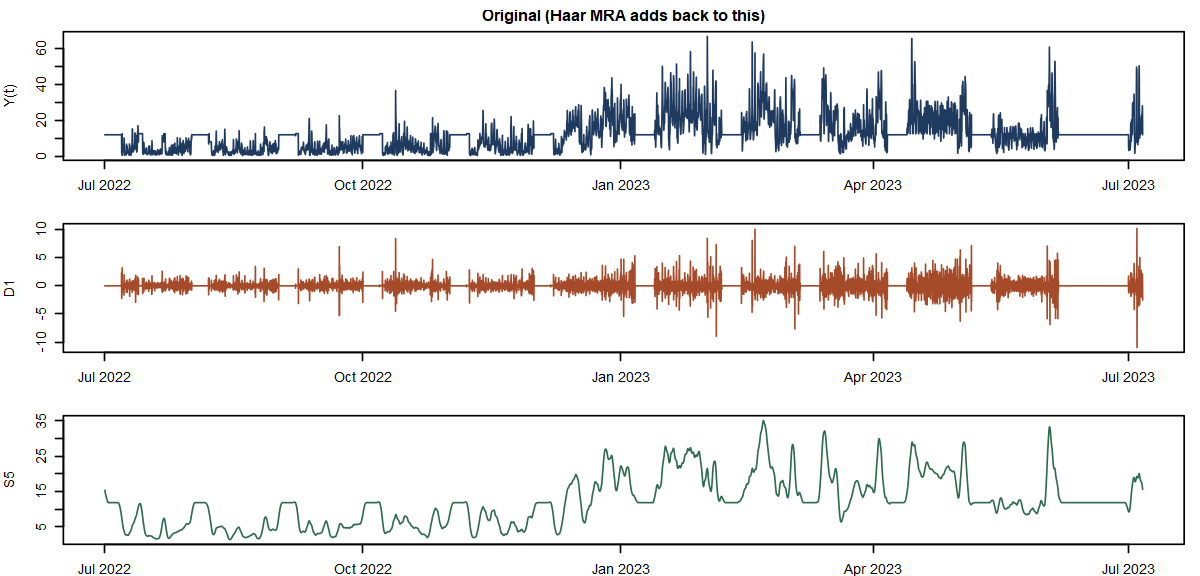

In [ ]:
J <- 5L
mra <- haar_mra(y, J)
rec <- mra_reconstruct(mra)
t <- s$times
layout(matrix(1:3, ncol = 1), heights = c(1, 1, 1))
par(mar = c(2, 4, 2, 1))
plot(t, y, type = "l", col = "#1F3A5F", ylab = "Y(t)", xlab = NA,
     main = "Original (Haar MRA adds back to this)")
plot(t, mra$D[[1]], type = "l", col = "#A64B2A", ylab = "D1", xlab = NA)
plot(t, mra$S, type = "l", col = "#2E6B4F", ylab = "S5", xlab = "Time")
cat("Max reconstruction error at J =", J, ":", signif(max(abs(rec - y)), 3), "\n")


## 5. Lag features

No future values: `lag_k = y_{t-k}`.


In [ ]:
cat("Lag matrix and PACF cutoff — see R/05_features.R (make_lags, pacf_cutoff).\n")


Lag matrix and PACF cutoff — see R/05_features.R (make_lags, pacf_cutoff).


## 6. Models without MODWT

Shared protocol: recursive one-step forecasts out to horizon $h$ (paper Algorithm 1, step 14). Chronological validation inside train (last 14 days) for early stopping.

- **Seasonal naive**, $S=24$: the MASE reference.
- **AR($p$)** / **SARIMA**: `auto.arima` with period 24, stepwise, small order caps.
- **XGBoost, LightGBM, CatBoost** on lag-$p$ features. CatBoost uses `boosting_type = "Ordered"` so gradients for time $t$ do not use the target at $t$.


In [ ]:
cat("Point models and dispatcher — see R/06_models.R (fit_and_forecast, recursive_tree_forecast).\n")


Point models and dispatcher — see R/06_models.R (fit_and_forecast, recursive_tree_forecast).


## 7. Wave hybrids, including WaveCatBoost

For each **training** series: Haar MRA → one model per component → recursive component forecasts → sum.

- WaveSARIMA: does MODWT help a **linear** model?
- WaveXGB / WaveLGBM: does MODWT help boosting regardless of Ordered vs default?
- **WaveCatBoost**: the paper method.

All Wave\* models share the same $J$ and $p$ as the non-wave trees, so the ablation is the transform, not a hidden extra lag.


In [ ]:
cat("Wave hybrids — see R/06_models.R (wave_fit_components, wave_forecast_components).\n")


Wave hybrids — see R/06_models.R (wave_fit_components, wave_forecast_components).


## 8. Hyperparameters

The letter never publishes `iterations`, depth, learning rate, or lag $p$. A small expanding-window grid is run **once** on CPCB PM2.5, 1-day split, using only the training prefix. Chosen $(p, \text{depth}, \eta, J)$ are then frozen for every pollutant, sensor, and horizon.


In [ ]:
hp_path <- file.path(RES_DIR, "hparams.rds")
if (!file.exists(hp_path)) {
  cat("No results/hparams.rds yet. Run run_experiments.R from the project root.\n")
} else {
  hp <- readRDS(hp_path)
  cat(hp$reason, "\n")
  cat("J (capped at 5 for modelling):", min(as.integer(hp$J), 5L), "\n")
  print(hp$params)
  if (!is.null(hp$grid_lgb)) {
    print(head(hp$grid_lgb, 8))
  }
}


Chosen p=24, depth=6, eta=0.05 from LGBM time-based CV (val MASE=1.848). J=9 from WaveLGBM CV. 
J (capped at 5 for modelling): 5 
$p
[1] 24

$nrounds
[1] 160

$max_depth
[1] 6

$eta
[1] 0.05

$early_stopping
[1] 30

$val_hours
[1] 336

$lgb_leaves
[1] 31

# A tibble: 8 × 6
  method     p max_depth   eta     J val_MASE
  <chr>  <int>     <int> <dbl> <int>    <dbl>
1 lgb       24         6  0.05    NA     1.85
2 lgb       24         4  0.05    NA     1.85
3 lgb       24         4  0.1     NA     2.01
4 lgb       48         4  0.05    NA     2.09
5 lgb       48         4  0.1     NA     2.10
6 lgb       48         6  0.1     NA     2.11
7 lgb       24         6  0.1     NA     2.30
8 lgb       48         6  0.05    NA     2.34


## 9. A live 12-step check (LightGBM)

Same idea as `R/smoke_test.R`: reconstruct Haar MRA, then a short LightGBM forecast. Not the full bake-off.


In [ ]:
x <- s$y[1:256]
mra_toy <- haar_mra(x, 5)
cat("MRA reconstruction max error:", signif(max(abs(mra_reconstruct(mra_toy) - x)), 4), "\n")

sp1 <- chrono_split(s$y, s$times, 24)
pr <- default_tree_params()
pr$nrounds <- 40L
pr$early_stopping <- 10L
sc1 <- minmax_fit(sp1$y_train)
ytr <- minmax_apply(sp1$y_train, sc1)
fc <- fit_and_forecast("lgb", ytr, h = 12, params = pr, J = 3)
yhat12 <- minmax_invert(fc$yhat, sc1)
cat("LGB 12-step MASE:", round(mase(sp1$y_train, sp1$y_test[1:12], yhat12), 3), "\n")


MRA reconstruction max error: 3.553e-15 


LGB 12-step MASE: 0.479 


## 10. Forecasts and conformal intervals

The authors' `Conformal Prediction.R` uses `caretForecast::conformalRegressor` on absolute residuals. That is **not** the paper. We implement the letter's weighted score

$$
CS_t = \frac{|Y_t - \hat Y_t|}{\hat U_t}, \qquad
PI_t = \hat Y_t \pm CQ_t\,\hat U_t,
$$

with $\hat U_t$ a rolling MAE, $CQ_t$ the $(1-\alpha)$ quantile of $CS$ on a trailing window of length $\kappa$, and $\alpha = 0.05$. $\kappa$ is chosen in $\{24,168,336\}$ so calibration coverage is closest to 95%. Test actuals are not used to build the band.

**Decision rule (ours, not the paper).** If the mean of the PM2.5 **lower** bound over the horizon exceeds the WHO (15 µg/m³) or India NAAQS (60 µg/m³) 24-hour guide, we flag “exceedance likely”.


In [ ]:
cat("Conformal intervals — see R/07_conformal.R (conformal_from_residuals, alert_from_interval).\n")


Conformal intervals — see R/07_conformal.R (conformal_from_residuals, alert_from_interval).


# A tibble: 4 × 11
  rule      threshold unit  mean_forecast mean_lower exceedance_likely sensor
  <chr>         <dbl> <chr>         <dbl>      <dbl> <lgl>             <chr> 
1 WHO_24h          15 ug/m3          11.9       11.7 FALSE             CPCB  
2 NAAQS_24h        60 ug/m3          11.9       11.7 FALSE             CPCB  
3 WHO_24h          15 ug/m3          13.7      -10.6 FALSE             ID1   
4 NAAQS_24h        60 ug/m3          13.7      -10.6 FALSE             ID1   
  coverage_test mean_width kappa min_lower
          <dbl>      <dbl> <int>     <dbl>
1         0.304      0.376   168      11.7
2         0.304      0.376   168      11.7
3         1         48.5     168     -17.5
4         1         48.5     168     -17.5

CPCB PM2.5 7-day: coverage=30%, mean width=0.38, min(lower)=11.67
ID1 PM2.5 7-day: coverage=100%, mean width=48.46, min(lower)=-17.53


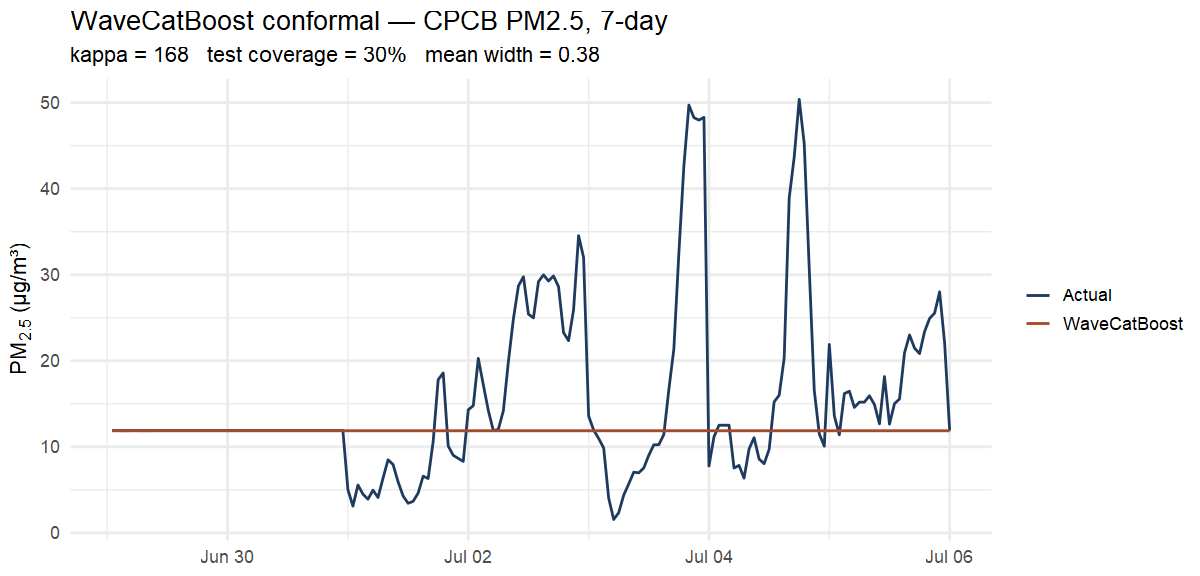

In [ ]:
conf_path <- file.path(RES_DIR, "conformal.rds")
if (!file.exists(conf_path)) {
  cat("No results/conformal.rds yet. Run run_conformal.R after the bake-off.\n")
} else {
  conf <- readRDS(conf_path)
  z <- conf[["CPCB"]]
  if (is.null(z)) z <- conf[[1]]
  cdf <- tibble(Datetime = z$t_test, actual = z$y_test, pred = z$yhat,
                lo = z$lower, hi = z$upper)
  print(
    ggplot(cdf, aes(Datetime)) +
      geom_ribbon(aes(ymin = lo, ymax = hi), fill = "#1F3A5F", alpha = 0.18) +
      geom_line(aes(y = actual, colour = "Actual")) +
      geom_line(aes(y = pred, colour = "WaveCatBoost")) +
      scale_colour_manual(values = c(Actual = "#1F3A5F", WaveCatBoost = "#A64B2A")) +
      labs(
        y = expression(PM[2.5]~"(µg/m³)"), x = NULL, colour = NULL,
        title = sprintf("WaveCatBoost conformal — %s PM2.5, 7-day", z$sensor),
        subtitle = sprintf("kappa = %s   test coverage = %.0f%%   mean width = %.2f",
                           z$kappa, 100 * z$coverage_test, z$width)
      )
  )
  alert_tbl <- dplyr::bind_rows(lapply(conf, function(w) {
    dplyr::mutate(w$alert, sensor = w$sensor, coverage_test = w$coverage_test,
                  mean_width = w$width, kappa = w$kappa,
                  min_lower = min(w$lower, na.rm = TRUE))
  }))
  print(alert_tbl, n = Inf, width = Inf)
  cat("\n")
  for (w in conf) {
    cat(sprintf("%s PM2.5 7-day: coverage=%.0f%%, mean width=%.2f, min(lower)=%.2f\n",
                w$sensor, 100 * w$coverage_test, w$width, min(w$lower, na.rm = TRUE)))
  }
}


These bands are **prediction intervals**, not confidence intervals for a mean.

**Reading.** CPCB 7-day coverage is only ~30% with mean width 0.38 — the band is too tight (undercoverage). ID1 coverage is 100% with mean width ~48 and a **negative** lower bound — the band is too wide, and concentrations cannot be negative. The conformal layer is not well calibrated on this split.


## 11. Comparison (cached bake-off)

`run_experiments.R` writes `results/scores.rds`. MASE uses seasonality 24. MAE and RMSE are on original units after inverting min-max.

Ablations to read off the table:

1. **CatBoost vs WaveCatBoost** (or LGB vs WaveLGB if CatBoost fell back): value of MODWT.
2. **WaveXGB vs WaveCatBoost**: value of Ordered boosting after the transform is fixed.
3. **SARIMA vs WaveSARIMA**: whether the transform helps a linear model, or only trees.


In [ ]:
score_path <- file.path(RES_DIR, "scores.rds")
if (!file.exists(score_path)) {
  cat("No results/scores.rds yet. From the project root:\n",
      "  Rscript run_experiments.R        # full 6 x 2 x 4 bake-off\n",
      "  Rscript run_experiments.R quick  # 1-day, snaive/sarima/lgb/wavelgb\n")
  scores <- NULL
} else {
  scores <- readRDS(score_path)
  cat("Cached forecasts:", nrow(scores), "\n")
  print(scores %>% dplyr::filter(pollutant == "PM2.5", horizon == "1d") %>%
          dplyr::mutate(dplyr::across(c(MASE, MAE, RMSE), ~ round(., 3))),
        n = Inf, width = Inf)
}


Cached forecasts: 432 
# A tibble: 18 × 8
   sensor pollutant horizon method        elapsed  MASE   MAE  RMSE
   <chr>  <chr>     <chr>   <chr>           <dbl> <dbl> <dbl> <dbl>
 1 CPCB   PM2.5     1d      snaive         0.110  2.02   8.57 11.4 
 2 CPCB   PM2.5     1d      sarima       278.     1.34   5.67  6.66
 3 CPCB   PM2.5     1d      xgb            3.03   1.37   5.80  7.42
 4 CPCB   PM2.5     1d      lgb            6.07   0.737  3.12  4.38
 5 CPCB   PM2.5     1d      catboost      34.0    0.821  3.48  4.19
 6 CPCB   PM2.5     1d      wavesarima    16.7    1.28   5.43  7.13
 7 CPCB   PM2.5     1d      wavexgb       16.6    1.20   5.07  5.92
 8 CPCB   PM2.5     1d      wavelgb       58.2    1.03   4.37  5.55
 9 CPCB   PM2.5     1d      wavecatboost 200.     0.712  3.02  3.73
10 ID1    PM2.5     1d      snaive         0.0500 0.71   8.20  9.55
11 ID1    PM2.5     1d      sarima        74.0    0.489  5.64  6.04
12 ID1    PM2.5     1d      xgb            2.62   0.869 10.0  10.3 
13 ID1

In [ ]:
if (!is.null(scores) && nrow(scores)) {
  wide <- scores %>%
    dplyr::filter(pollutant == "PM2.5") %>%
    dplyr::select(sensor, pollutant, horizon, method, MASE) %>%
    tidyr::pivot_wider(names_from = method, values_from = MASE)
  print(wide %>% dplyr::mutate(dplyr::across(where(is.numeric), ~ round(., 3))),
        n = Inf, width = Inf)
}


# A tibble: 8 × 12
  sensor pollutant horizon snaive sarima   xgb   lgb catboost wavesarima wavexgb
  <chr>  <chr>     <chr>    <dbl>  <dbl> <dbl> <dbl>    <dbl>      <dbl>   <dbl>
1 CPCB   PM2.5     1d       2.02   1.34  1.37  0.737    0.821      1.28    1.20 
2 ID1    PM2.5     1d       0.71   0.489 0.869 0.844    0.672      0.169   0.374
3 CPCB   PM2.5     7d       1.50   1.50  1.50  1.50     1.50       1.50    1.50 
4 ID1    PM2.5     7d       0.751  0.624 0.789 0.736    0.619      0.426   0.525
5 CPCB   PM2.5     14d      0.734  0.734 0.734 0.749    0.775      0.734   0.734
6 ID1    PM2.5     14d      0.758  0.713 0.655 0.654    0.686      0.693   0.693
7 CPCB   PM2.5     31d      2.87   2.95  2.48  2.28     2.39       1.00    0.619
8 ID1    PM2.5     31d      0.548  0.554 0.575 0.569    0.549      0.548   1.23 
  wavelgb wavecatboost
    <dbl>        <dbl>
1   1.03         0.712
2   0.36         0.415
3   1.50         1.50 
4   0.54         0.59 
5   0.735        0.754
6   0.691 

# A tibble: 9 × 5
  model        mean_rank critical_distance    lo    hi
  <chr>            <dbl>             <dbl> <dbl> <dbl>
1 wavesarima        4.47              1.73  3.60  5.34
2 wavelgb           4.69              1.73  3.82  5.55
3 wavecatboost      4.92              1.73  4.05  5.78
4 lgb               5.02              1.73  4.15  5.89
5 sarima            5.05              1.73  4.19  5.92
6 wavexgb           5.12              1.73  4.26  5.99
7 snaive            5.19              1.73  4.32  6.05
8 catboost          5.19              1.73  4.32  6.05
9 xgb               5.35              1.73  4.49  6.22
No model is significantly best — all rank intervals overlap 


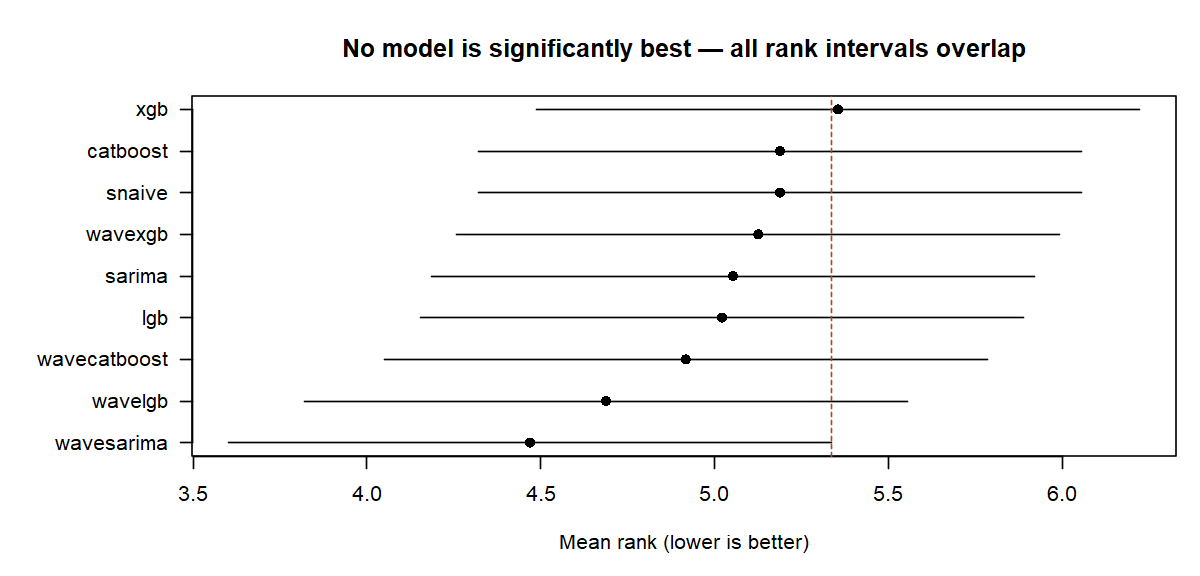

In [ ]:
if (!is.null(scores) && nrow(scores) > 4) {
  mcb <- tryCatch(mcb_from_table(scores), error = function(e) NULL)
  if (!is.null(mcb)) {
    print(mcb, n = Inf, width = Inf)
    best_hi <- mcb$hi[1]
    n_sig_worse <- sum(mcb$lo > best_hi)
    headline <- if (n_sig_worse == 0L) {
      "No model is significantly best — all rank intervals overlap"
    } else {
      sprintf("%d model(s) significantly worse than %s", n_sig_worse, mcb$model[1])
    }
    cat(headline, "\n")
    rng <- range(c(mcb$lo, mcb$hi))
    par(mar = c(5, 8, 4, 1))
    plot(mcb$mean_rank, seq_len(nrow(mcb)), pch = 16, xlim = rng,
         yaxt = "n", xlab = "Mean rank (lower is better)", ylab = NA,
         main = headline)
    axis(2, at = seq_len(nrow(mcb)), labels = mcb$model, las = 1)
    segments(mcb$lo, seq_len(nrow(mcb)), mcb$hi, seq_len(nrow(mcb)))
    abline(v = min(mcb$mean_rank) + unique(mcb$critical_distance) / 2,
           lty = 2, col = "#A64B2A")
  }
}


# A tibble: 1 × 3
   MASE   MAE  RMSE
  <dbl> <dbl> <dbl>
1 0.712  3.02  3.73


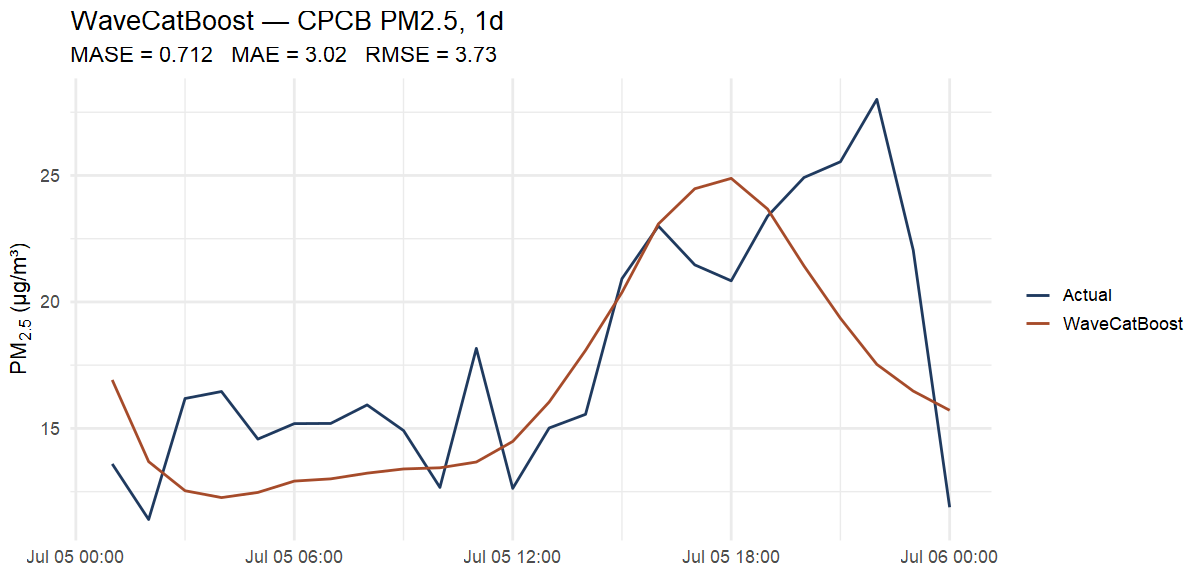

In [ ]:
cache_path <- file.path(RES_DIR, "forecast_cache.rds")
if (file.exists(cache_path)) {
  cache <- readRDS(cache_path)
  key <- "CPCB|PM2.5|1d|wavecatboost"
  z <- cache[[key]]
  if (!is.null(z) && !isTRUE(z$error)) {
    fdf <- tibble(Datetime = z$t_test, actual = z$y_test, pred = z$yhat)
    print(
      ggplot(fdf, aes(Datetime)) +
        geom_line(aes(y = actual, colour = "Actual")) +
        geom_line(aes(y = pred, colour = "WaveCatBoost")) +
        scale_colour_manual(values = c(Actual = "#1F3A5F", WaveCatBoost = "#A64B2A")) +
        labs(
          title = sprintf("WaveCatBoost — %s %s, %s", z$sensor, z$pollutant, z$horizon),
          subtitle = sprintf("MASE = %.3f   MAE = %.2f   RMSE = %.2f",
                             z$scores$MASE, z$scores$MAE, z$scores$RMSE),
          y = expression(PM[2.5]~"(µg/m³)"), x = NULL, colour = NULL
        )
    )
    print(z$scores)
  } else {
    cat("No cached WaveCatBoost 1-day CPCB PM2.5 forecast.\n")
  }
} else {
  cat("No results/forecast_cache.rds yet.\n")
}


## 12. Limitations (do not over-claim)

- GitHub hourly files are not the original 15-minute traces; CPCB looks pre-imputed.
- MASE will **not** match paper Table 1. We omitted deep-learning baselines (by design), and the letter never published boosting hyperparameters.
- Circular MODWT splits scales; it does not “remove all noise”.
- Recursive multi-step forecasts accumulate error at 14- and 31-day horizons.
- The alert rule is a course-level extra, not part of the letter.

Full bake-off (from the project root):

```bat
"C:\Program Files\R\R-4.5.1\bin\Rscript.exe" run_experiments.R
"C:\Program Files\R\R-4.5.1\bin\Rscript.exe" run_conformal.R
```

Then re-run the cells in sections 10–11, or open `analysis.Rmd` in RStudio (**Run Document**) for the interactive report.
